In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
from src.utils.config import *
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)

# 06 Customer lifetime value (regression)
Target = sum of successful payments to date. Features contain **no payment-derived columns**.

,model,cv_r2,MAE,RMSE,R2
0,Random Forest,0.977,10.092,13.669,0.979
1,XGBoost,0.977,10.256,13.789,0.978
2,Linear Regression,0.852,25.558,38.450,0.832


CLV mean/std: 174.5 93.1


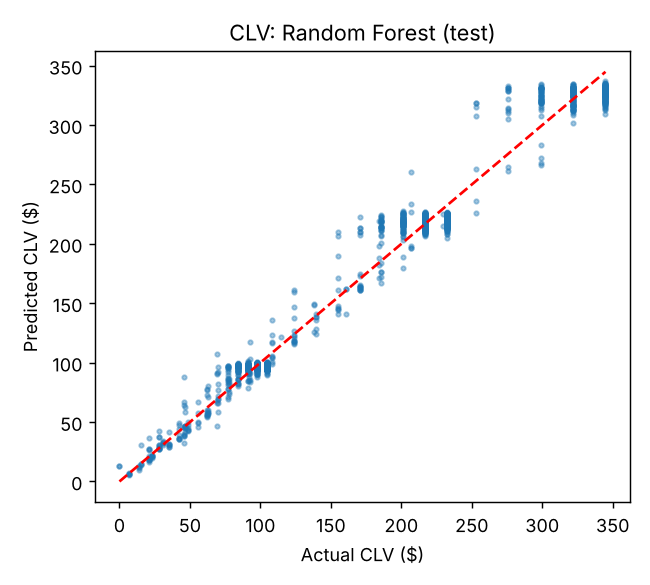

In [2]:
rep = json.load(open(REPORTS/'model_report.json')); display(pd.DataFrame(rep['clv_comparison']).round(3)); print('CLV mean/std:', round(rep['clv_target_mean'],1), round(rep['clv_target_std'],1)); display(Image(filename=str(FIGURES/'model_clv_actual_vs_pred.png'), width=420))

## Read this before putting R² = 0.98 on a resume
The tree models explain 98% of variance, but **that is mostly arithmetic, not insight**: CLV is roughly *months subscribed x plan price*, and tenure and plan price are features. Linear regression already gets R² 0.83 and the trees mostly learn the cap (payments are limited to 15 per customer) and plan-price steps. The model is fine for filling in value for the retention rules; it is not a discovery. MAE ~ $10 on a mean of ~$175.